# Step 2 — Data Quality & Evaluation Preparation
**Role:** Data & Evaluation  
**Dataset:** `handwritten_digits_data.npz` (handwritten digit images)

**Name:** Amirhossein Hassani

summery: najafzadeh and dehghani tasks have been completed, and I should prepare the data for training and test.

## Goal
Check the dataset for errors and quality problems, document any issues found, create a reproducible stratified validation split from the original training data, and keep the original test set unchanged for the final evaluation.



## 1. Imports and configuration

Place `handwritten_digits_data.npz` in the same directory as this notebook, or update `DATA_PATH` below. The split seed is fixed so the validation split can be reproduced.

Before working with images of handwritten digits, it imports the necessary libraries, defines file paths and configuration values, checks whether the input dataset exists, and prints the locations of the input and output files.

In [12]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

DATA_PATH = Path("handwritten_digits_data.npz")
OUTPUT_PATH = Path("prepared_handwritten_digits_data.npz")
RANDOM_STATE = 42
VALIDATION_SIZE = 0.20

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Place handwritten_digits_data.npz beside this notebook or update DATA_PATH."
    )

print(f"Input: {DATA_PATH.resolve()}")
print(f"Output: {OUTPUT_PATH.resolve()}")

Input: C:\Users\Deniz-pc\Downloads\handwritten_digits_data.npz
Output: C:\Users\Deniz-pc\Downloads\prepared_handwritten_digits_data.npz


## 2. Load data and check required arrays

the code verifies the dataset, loads four arrays, and displays their dimensions and data types so you can check that the data is ready for machine learning.

In [13]:
with np.load(DATA_PATH, allow_pickle=False) as data:
    required_keys = {"train_images", "train_labels", "test_images", "test_labels"}
    missing = required_keys - set(data.files)
    if missing:
        raise KeyError(f"Missing required arrays: {sorted(missing)}")
    train_images = data["train_images"].copy()
    train_labels = data["train_labels"].copy()
    test_images = data["test_images"].copy()
    test_labels = data["test_labels"].copy()

print("Loaded arrays:")
for name, array in [
    ("train_images", train_images), ("train_labels", train_labels),
    ("test_images", test_images), ("test_labels", test_labels)
]:
    print(f"  {name:14s} shape={array.shape}, dtype={array.dtype}")

Loaded arrays:
  train_images   shape=(59999, 28, 28), dtype=uint8
  train_labels   shape=(59999,), dtype=int64
  test_images    shape=(9999, 28, 28), dtype=uint8
  test_labels    shape=(9999,), dtype=int64


## 3. Validate shapes, values, labels, and missing values

this code catches dataset problems early, helping prevent errors when training a machine learning model.

In [14]:
def validate_split(images, labels, split_name):
    errors = []
    if images.ndim != 3 or images.shape[1:] != (28, 28):
        errors.append(f"{split_name}: images must have shape (N, 28, 28); got {images.shape}")
    if labels.ndim != 1:
        errors.append(f"{split_name}: labels must be one-dimensional; got {labels.shape}")
    if len(images) != len(labels):
        errors.append(f"{split_name}: image/label count mismatch ({len(images)} vs {len(labels)})")
    if len(images) == 0:
        errors.append(f"{split_name}: split is empty")
    if not np.issubdtype(images.dtype, np.number):
        errors.append(f"{split_name}: image array must be numeric")
    elif not np.isfinite(images).all():
        errors.append(f"{split_name}: images contain NaN or infinite values")
    elif images.min() < 0 or images.max() > 255:
        errors.append(f"{split_name}: pixel values fall outside [0, 255]")
    if not np.issubdtype(labels.dtype, np.integer):
        errors.append(f"{split_name}: labels must use an integer dtype")
    elif not np.isin(labels, np.arange(10)).all():
        errors.append(f"{split_name}: labels must be in the range 0–9")
    if errors:
        raise ValueError("\\n".join(errors))

validate_split(train_images, train_labels, "train")
validate_split(test_images, test_labels, "test")
print("PASS: shapes, lengths, finite pixels, pixel range, and labels are valid.")

PASS: shapes, lengths, finite pixels, pixel range, and labels are valid.


the code compares the training and test datasets by checking their sizes, pixel ranges, blank images, and number of distinct classes.

In [15]:
def split_summary(images, labels, split_name):
    blank_count = int(np.count_nonzero(images.reshape(len(images), -1).max(axis=1) == 0))
    return {
        "split": split_name,
        "samples": int(len(labels)),
        "image_shape": str(tuple(images.shape[1:])),
        "pixel_min": int(images.min()),
        "pixel_max": int(images.max()),
        "blank_images": blank_count,
        "unique_labels": int(np.unique(labels).size),
    }

quality_summary = pd.DataFrame([
    split_summary(train_images, train_labels, "original_train"),
    split_summary(test_images, test_labels, "official_test"),
])
display(quality_summary)

,split,samples,image_shape,pixel_min,pixel_max,blank_images,unique_labels
0,original_train,59999,"(28, 28)",0,255,0,10
1,official_test,9999,"(28, 28)",0,255,0,10


## 4. Inspect class balance

This code counts the images for each digit (0–9) in the training and testing sets and displays the results in a table. It plots a bar chart to compare the class distributions and checks whether all ten digit classes are present in both sets, printing a warning if any class is missing.

,digit,train_count,test_count
0,0,5999,999
1,1,6000,1000
2,2,6000,1000
3,3,6000,1000
4,4,6000,1000
5,5,6000,1000
6,6,6000,1000
7,7,6000,1000
8,8,6000,1000
9,9,6000,1000


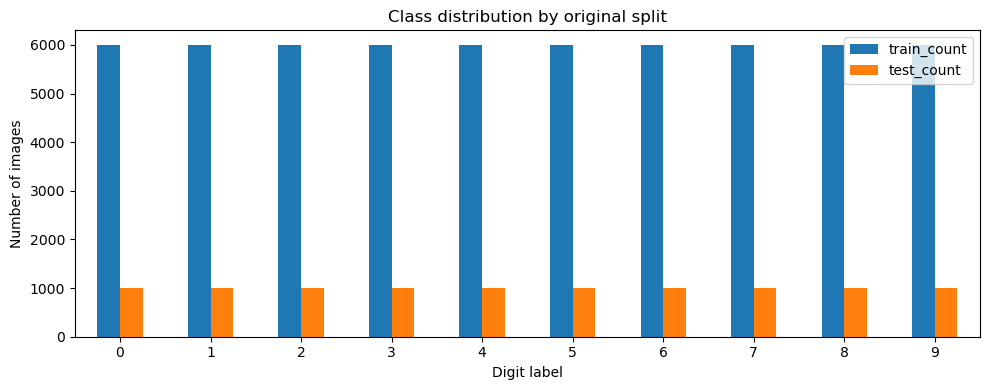

PASS: all ten digit classes are represented in both original splits.


In [16]:
train_counts = pd.Series(train_labels).value_counts().reindex(range(10), fill_value=0).sort_index()
test_counts = pd.Series(test_labels).value_counts().reindex(range(10), fill_value=0).sort_index()
class_balance = pd.DataFrame({
    "digit": range(10),
    "train_count": train_counts.to_numpy(),
    "test_count": test_counts.to_numpy(),
})
display(class_balance)

ax = class_balance.set_index("digit")[["train_count", "test_count"]].plot(kind="bar", figsize=(10, 4))
ax.set_title("Class distribution by original split")
ax.set_xlabel("Digit label")
ax.set_ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

if (class_balance[["train_count", "test_count"]] == 0).any().any():
    print("WARNING: at least one digit class is absent from a split.")
else:
    print("PASS: all ten digit classes are represented in both original splits.")

## 5. Audit exact duplicate images

This code calculates a SHA-256 hash for each image to identify exact duplicates. It counts duplicates within the training and test sets and finds identical images shared between both sets. The results are displayed in a table to help detect duplicate data and prevent data leakage between training and validation.

In [17]:
def image_hashes(images):
    return [hashlib.sha256(np.ascontiguousarray(img).tobytes()).hexdigest() for img in images]

train_hashes = image_hashes(train_images)
test_hashes = image_hashes(test_images)
train_hash_set = set(train_hashes)
test_hash_set = set(test_hashes)

train_duplicate_excess = len(train_hashes) - len(train_hash_set)
test_duplicate_excess = len(test_hashes) - len(test_hash_set)
cross_split_hashes = train_hash_set & test_hash_set

duplicate_audit = pd.DataFrame([
    {"check": "Duplicate excess within original train", "count": int(train_duplicate_excess)},
    {"check": "Duplicate excess within official test", "count": int(test_duplicate_excess)},
    {"check": "Unique images appearing in both train and test", "count": int(len(cross_split_hashes))},
])
display(duplicate_audit)
print("Exact duplicates are audited explicitly before splitting to avoid train/validation leakage.")

,check,count
0,Duplicate excess within original train,5045
1,Duplicate excess within official test,1
2,Unique images appearing in both train and test,12


Exact duplicates are audited explicitly before splitting to avoid train/validation leakage.


## 6. Prepare a leakage-aware development pool

This code cleans the training data by removing images with conflicting labels, images that also appear in the official test set, and repeated copies of identical images. It displays a summary of the removed and remaining samples, checks that data remains for all ten digit classes, and splits the cleaned data into training and validation sets while preserving class proportions. The original test set remains unchanged.

In [18]:
# Group original training examples by exact pixel hash.
# Conflicting labels for identical pixels are ambiguous and excluded from development data.
hash_to_labels = {}
for h, label in zip(train_hashes, train_labels):
    hash_to_labels.setdefault(h, set()).add(int(label))

conflicting_hashes = {h for h, labels in hash_to_labels.items() if len(labels) > 1}
test_overlap_hashes = set(test_hashes)

keep_indices = []
seen_hashes = set()
removed_conflicting = 0
removed_test_overlap = 0
removed_duplicate_copies = 0

for idx, h in enumerate(train_hashes):
    if h in conflicting_hashes:
        removed_conflicting += 1
        continue
    if h in test_overlap_hashes:
        removed_test_overlap += 1
        continue
    if h in seen_hashes:
        removed_duplicate_copies += 1
        continue
    seen_hashes.add(h)
    keep_indices.append(idx)

development_images = train_images[keep_indices]
development_labels = train_labels[keep_indices]

cleaning_summary = pd.DataFrame([
    {"action": "Original training samples", "count": int(len(train_images))},
    {"action": "Removed samples with conflicting labels for identical pixels", "count": int(removed_conflicting)},
    {"action": "Removed samples overlapping official test by exact pixels", "count": int(removed_test_overlap)},
    {"action": "Removed repeated exact-image copies from development pool", "count": int(removed_duplicate_copies)},
    {"action": "Remaining unique development samples", "count": int(len(development_labels))},
])
display(cleaning_summary)

if len(development_labels) == 0:
    raise ValueError("No development samples remain after duplicate/leakage checks.")
if set(np.unique(development_labels)) != set(range(10)):
    raise ValueError("At least one digit class is absent after cleaning; inspect cleaning_summary before proceeding.")

X_train, X_val, y_train, y_val = train_test_split(
    development_images,
    development_labels,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=development_labels,
)

print(f"Train:      {len(y_train):,} unique samples")
print(f"Validation: {len(y_val):,} unique samples")
print(f"Test:       {len(test_labels):,} samples (original official test; unchanged)")

,action,count
0,Original training samples,59999
1,Removed samples with conflicting labels for id...,0
2,Removed samples overlapping official test by e...,23
3,Removed repeated exact-image copies from devel...,5034
4,Remaining unique development samples,54942


Train:      43,953 unique samples
Validation: 10,989 unique samples
Test:       9,999 samples (original official test; unchanged)


## 7. Verify class balance and split integrity

This code displays the number of images for each digit in the training, validation, and test sets, then uses assertions to verify dataset sizes and class coverage. It checks for identical images shared between splits and raises an error if any overlap is found, confirming that the datasets are properly separated.

In [19]:
split_class_balance = pd.DataFrame({
    "digit": range(10),
    "train": pd.Series(y_train).value_counts().reindex(range(10), fill_value=0).to_numpy(),
    "validation": pd.Series(y_val).value_counts().reindex(range(10), fill_value=0).to_numpy(),
    "test": pd.Series(test_labels).value_counts().reindex(range(10), fill_value=0).to_numpy(),
})
display(split_class_balance)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(test_images) == len(test_labels)
assert set(np.unique(y_train)) == set(range(10))
assert set(np.unique(y_val)) == set(range(10))
assert set(np.unique(test_labels)) == set(range(10))

new_train_hashes = set(image_hashes(X_train))
val_hash_set = set(image_hashes(X_val))
official_test_hash_set = set(test_hashes)

overlap_report = pd.DataFrame([
    {"pair": "train vs validation", "shared_unique_exact_images": len(new_train_hashes & val_hash_set)},
    {"pair": "train vs official test", "shared_unique_exact_images": len(new_train_hashes & official_test_hash_set)},
    {"pair": "validation vs official test", "shared_unique_exact_images": len(val_hash_set & official_test_hash_set)},
])
display(overlap_report)

if overlap_report["shared_unique_exact_images"].sum() != 0:
    raise AssertionError("Exact-image overlap remains between prepared splits.")
print("PASS: no exact-image overlap across train, validation, and official test.")

,digit,train,validation,test
0,0,4398,1100,999
1,1,4355,1089,1000
2,2,4400,1100,1000
3,3,4400,1100,1000
4,4,4400,1100,1000
5,5,4400,1100,1000
6,6,4400,1100,1000
7,7,4400,1100,1000
8,8,4400,1100,1000
9,9,4400,1100,1000


,pair,shared_unique_exact_images
0,train vs validation,0
1,train vs official test,0
2,validation vs official test,0


PASS: no exact-image overlap across train, validation, and official test.


## 8. Save prepared data and a machine-readable audit report

This code saves the prepared training, validation, and test datasets in a compressed NumPy file and creates a JSON audit report containing dataset sizes, cleaning statistics, and quality checks. It then prints the saved file paths, file size, and full report for verification and future reference.

In [9]:
np.savez_compressed(
    OUTPUT_PATH,
    train_images=X_train,
    train_labels=y_train,
    validation_images=X_val,
    validation_labels=y_val,
    test_images=test_images,
    test_labels=test_labels,
)

audit_report = {
    "input_file": DATA_PATH.name,
    "output_file": OUTPUT_PATH.name,
    "random_state": RANDOM_STATE,
    "validation_fraction": VALIDATION_SIZE,
    "counts": {
        "original_train": int(len(train_images)),
        "prepared_train": int(len(X_train)),
        "validation": int(len(X_val)),
        "official_test_unchanged": int(len(test_images)),
    },
    "cleaning": {
        "removed_conflicting_label_samples": int(removed_conflicting),
        "removed_exact_overlaps_with_official_test": int(removed_test_overlap),
        "removed_duplicate_copies_from_development_pool": int(removed_duplicate_copies),
    },
    "quality": {
        "blank_images_original_train": int(np.count_nonzero(train_images.reshape(len(train_images), -1).max(axis=1) == 0)),
        "blank_images_official_test": int(np.count_nonzero(test_images.reshape(len(test_images), -1).max(axis=1) == 0)),
        "duplicate_excess_original_train": int(train_duplicate_excess),
        "duplicate_excess_official_test": int(test_duplicate_excess),
        "shared_unique_exact_images_original_train_test": int(len(cross_split_hashes)),
        "prepared_split_exact_overlap_total": int(overlap_report["shared_unique_exact_images"].sum()),
    },
    "note": "Official test set preserved unchanged. Exact duplicates and cross-split overlap are handled explicitly. Near-duplicates and writer-level leakage are not detected. Verify dataset source and license."
}
REPORT_PATH = Path("data_quality_report.json")
REPORT_PATH.write_text(json.dumps(audit_report, indent=2), encoding="utf-8")

print(f"Saved prepared dataset: {OUTPUT_PATH.resolve()}")
print(f"Saved audit report:    {REPORT_PATH.resolve()}")
print(f"Prepared dataset size: {OUTPUT_PATH.stat().st_size / (1024**2):.2f} MiB")
print("\nAudit report:")
print(json.dumps(audit_report, indent=2))

Saved prepared dataset: /mnt/data/prepared_handwritten_digits_data.npz
Saved audit report:    /mnt/data/data_quality_report.json
Prepared dataset size: 9.66 MiB

Audit report:
{
  "input_file": "handwritten_digits_data.npz",
  "output_file": "prepared_handwritten_digits_data.npz",
  "random_state": 42,
  "validation_fraction": 0.2,
  "counts": {
    "original_train": 59999,
    "prepared_train": 43953,
    "validation": 10989,
    "official_test_unchanged": 9999
  },
  "cleaning": {
    "removed_conflicting_label_samples": 0,
    "removed_exact_overlaps_with_official_test": 23,
    "removed_duplicate_copies_from_development_pool": 5034
  },
  "quality": {
    "blank_images_original_train": 0,
    "blank_images_official_test": 0,
    "duplicate_excess_original_train": 5045,
    "duplicate_excess_official_test": 1,
    "shared_unique_exact_images_original_train_test": 12,
    "prepared_split_exact_overlap_total": 0
  },
  "note": "Official test set preserved unchanged. Exact duplicates a

## 9. Deliverables and handoff notes

- `prepared_handwritten_digits_data.npz`: prepared train/validation arrays and the unchanged official test set.
- `data_quality_report.json`: machine-readable quality, duplicate, and cleaning summary.
- This notebook: validation logic, class-balance tables, leakage-aware split procedure, and reproducible preparation.

### Limitations to document in the report
1. Verify and cite the original dataset source and license.
2. Exact-pixel hashing does not identify near-duplicate images or writer-level leakage.
3. No classifier has been trained here. Later, report accuracy, precision, recall, F1, and a confusion matrix using predictions on the untouched test set.
4. Do not use the official test set to select features, tune hyperparameters, or choose a model.
5. The cleaning policy intentionally removes exact duplicates from the development pool and excludes training examples identical to official test images; disclose these counts in the report.